In [1]:

# Stock Return Prediction Using Machine Learning

!pip -q install yfinance scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Step 2: Download historical SPY data

ticker = "SPY"

data = yf.download(
    ticker,
    start="2020-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

# Extract adjusted closing prices
prices = data["Close"].copy()

# Handle possible multi-level columns
if isinstance(prices, pd.DataFrame):
    prices = prices.iloc[:, 0]

prices.name = "Close"

print("First five prices:")
print(prices.head())

print("\nLast five prices:")
print(prices.tail())

print("\nTotal trading days:", len(prices))


First five prices:
Date
2020-01-02    295.391785
2020-01-03    293.154938
2020-01-06    294.273438
2020-01-07    293.445923
2020-01-08    295.009979
Name: Close, dtype: float64

Last five prices:
Date
2025-12-24    685.029480
2025-12-26    684.959961
2025-12-29    682.519043
2025-12-30    681.685608
2025-12-31    676.635010
Name: Close, dtype: float64

Total trading days: 1508


In [3]:

# Step 3: Calculate daily returns

df = pd.DataFrame({
    "Close": prices
})

df["Daily_Return"] = df["Close"].pct_change()

print(df.head(10))


                 Close  Daily_Return
Date                                
2020-01-02  295.391785           NaN
2020-01-03  293.154938     -0.007572
2020-01-06  294.273438      0.003815
2020-01-07  293.445923     -0.002812
2020-01-08  295.009979      0.005330
2020-01-09  297.010315      0.006781
2020-01-10  296.155579     -0.002878
2020-01-13  298.192291      0.006877
2020-01-14  297.737640     -0.001525
2020-01-15  298.410553      0.002260


In [4]:

# Step 4: Feature engineering

# Most recent daily return
df["Return_1D"] = df["Daily_Return"]

# Cumulative return over the last 5 trading days
df["Return_5D"] = df["Close"].pct_change(5)

# Rolling volatility over the last 5 trading days
df["Volatility_5D"] = (
    df["Daily_Return"].rolling(5).std()
)

# Price relative to its 20-day moving average
df["MA_20"] = df["Close"].rolling(20).mean()

df["MA_Ratio"] = (
    df["Close"] / df["MA_20"] - 1
)

print(df.tail(10))


                 Close  Daily_Return  Return_1D  Return_5D  Volatility_5D  \
Date                                                                        
2025-12-17  664.233765     -0.011004  -0.011004  -0.023518       0.005911   
2025-12-18  669.249695      0.007551   0.007551  -0.018428       0.007671   
2025-12-19  675.315369      0.009063   0.009063   0.001234       0.008210   
2025-12-22  679.522522      0.006230   0.006230   0.008996       0.008514   
2025-12-23  682.628235      0.004570   0.004570   0.016384       0.008156   
2025-12-24  685.029480      0.003518   0.003518   0.031308       0.002229   
2025-12-26  684.959961     -0.000101  -0.000101   0.023474       0.003385   
2025-12-29  682.519043     -0.003564  -0.003564   0.010667       0.003940   
2025-12-30  681.685608     -0.001221  -0.001221   0.003183       0.003369   
2025-12-31  676.635010     -0.007409  -0.007409  -0.008780       0.004064   

                 MA_20  MA_Ratio  
Date                              
2025-

In [5]:

# Step 5: Create next-day return target

df["Target"] = df["Daily_Return"].shift(-1)

# Select our model features
features = [
    "Return_1D",
    "Return_5D",
    "Volatility_5D",
    "MA_Ratio"
]

# Remove rows with missing features or targets
model_data = df.dropna(
    subset=features + ["Target"]
).copy()

print(model_data[features + ["Target"]].head())

print("\nTotal usable observations:", len(model_data))


            Return_1D  Return_5D  Volatility_5D  MA_Ratio    Target
Date                                                               
2020-01-30   0.003246  -0.012179       0.010346  0.001354 -0.018158
2020-01-31  -0.018158  -0.021413       0.012420 -0.016357  0.007428
2020-02-03   0.007428   0.001917       0.011236 -0.009309  0.015241
2020-02-04   0.015241   0.006638       0.012438  0.004958  0.011548
2020-02-05   0.011548   0.019105       0.013101  0.014993  0.003365

Total usable observations: 1488


In [6]:

# Step 6: Chronological train/test split

train = model_data[
    model_data.index < "2025-01-01"
].copy()

test = model_data[
    model_data.index >= "2025-01-01"
].copy()

X_train = train[features]
y_train = train["Target"]

X_test = test[features]
y_test = test["Target"]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())


Training observations: 1239
Testing observations: 249

Training period:
2020-01-30 00:00:00 to 2024-12-31 00:00:00

Testing period:
2025-01-02 00:00:00 to 2025-12-30 00:00:00


In [7]:

# Remove the final training row to avoid target overlap

train = train.iloc[:-1].copy()

X_train = train[features]
y_train = train["Target"]

print("Final training observations:", len(train))
print("Test observations:", len(test))


Final training observations: 1238
Test observations: 249


In [8]:

# Step 9: Train a linear regression model

model = LinearRegression()

# Learn relationships from 2020-2024 training data
model.fit(X_train, y_train)

print("Model trained successfully!")

print("\nModel Intercept:")
print(model.intercept_)

print("\nFeature Coefficients:")
for feature, coefficient in zip(features, model.coef_):
    print(f"{feature}: {coefficient:.6f}")


Model trained successfully!

Model Intercept:
0.002077001962429197

Feature Coefficients:
Return_1D: -0.160737
Return_5D: 0.030767
Volatility_5D: -0.122380
MA_Ratio: -0.030762


In [9]:

# Step 10: Generate predictions

y_pred = model.predict(X_test)

# Create a DataFrame to compare predictions
predictions = pd.DataFrame({
    "Actual_Return": y_test,
    "Predicted_Return": y_pred
}, index=X_test.index)

print("First 10 predictions:")
print(predictions.head(10))


First 10 predictions:
            Actual_Return  Predicted_Return
Date                                       
2025-01-02       0.012503          0.001651
2025-01-03       0.005761         -0.001344
2025-01-06      -0.011304          0.000087
2025-01-07       0.001461          0.003141
2025-01-08      -0.015267          0.001199
2025-01-10       0.001551          0.003570
2025-01-13       0.001376          0.000735
2025-01-14       0.018190          0.000655
2025-01-15      -0.001923         -0.002170
2025-01-16       0.010040          0.000972


In [10]:

# Step 11: Evaluate model accuracy

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

print(f"Mean Absolute Error: {mae:.4%}")
print(f"Root Mean Squared Error: {rmse:.4%}")


Mean Absolute Error: 0.7400%
Root Mean Squared Error: 1.2161%


In [11]:

# Step 12: Zero-return baseline

baseline_predictions = np.zeros(len(y_test))

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_predictions
    )
)

print("Linear Regression:")
print(f"MAE: {mae:.4%}")
print(f"RMSE: {rmse:.4%}")

print("\nZero-Return Baseline:")
print(f"MAE: {baseline_mae:.4%}")
print(f"RMSE: {baseline_rmse:.4%}")


Linear Regression:
MAE: 0.7400%
RMSE: 1.2161%

Zero-Return Baseline:
MAE: 0.7486%
RMSE: 1.2296%


In [12]:

# Step 13: Compare model and baseline

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Zero-Return Baseline"
    ],
    "MAE (%)": [
        mae * 100,
        baseline_mae * 100
    ],
    "RMSE (%)": [
        rmse * 100,
        baseline_rmse * 100
    ]
})

display(results.round(4))


,Model,MAE (%),RMSE (%)
0,Linear Regression,0.7400,1.2161
1,Zero-Return Baseline,0.7486,1.2296


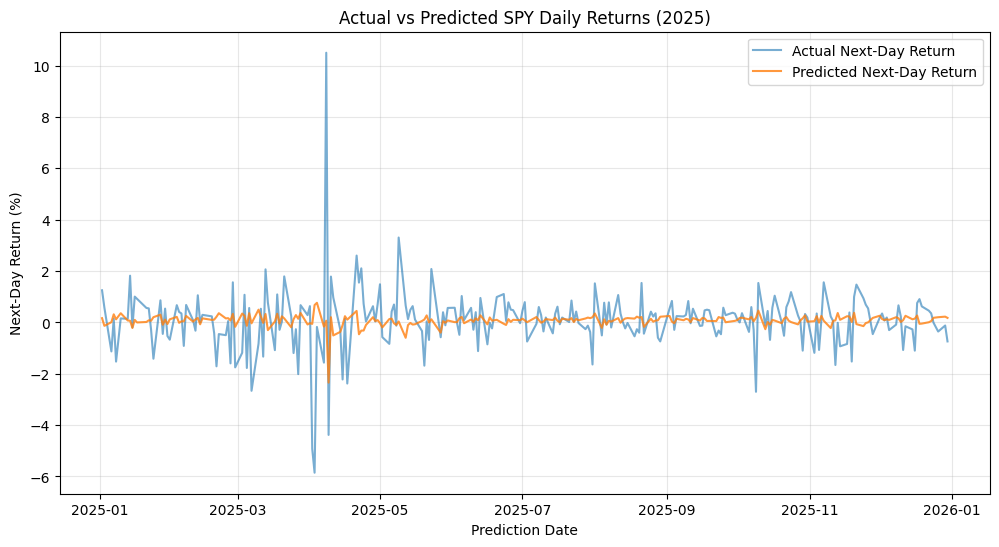

In [13]:

# Step 14: Plot actual and predicted returns

plt.figure(figsize=(12, 6))

plt.plot(
    predictions.index,
    predictions["Actual_Return"] * 100,
    label="Actual Next-Day Return",
    alpha=0.6
)

plt.plot(
    predictions.index,
    predictions["Predicted_Return"] * 100,
    label="Predicted Next-Day Return",
    alpha=0.8
)

plt.title("Actual vs Predicted SPY Daily Returns (2025)")
plt.xlabel("Prediction Date")
plt.ylabel("Next-Day Return (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [14]:

# Step 16: Additional model evaluation

from sklearn.metrics import r2_score

# R-squared
model_r2 = r2_score(y_test, y_pred)

# Directional accuracy
actual_direction = (y_test.to_numpy() > 0)
predicted_direction = (y_pred > 0)

directional_accuracy = np.mean(
    actual_direction == predicted_direction
)

# Compare against always predicting a positive return
positive_baseline_accuracy = np.mean(actual_direction)

print(f"Model R-squared: {model_r2:.4f}")
print(f"Directional Accuracy: {directional_accuracy:.2%}")
print(f"Always-Positive Baseline: {positive_baseline_accuracy:.2%}")


Model R-squared: 0.0183
Directional Accuracy: 56.22%
Always-Positive Baseline: 57.43%


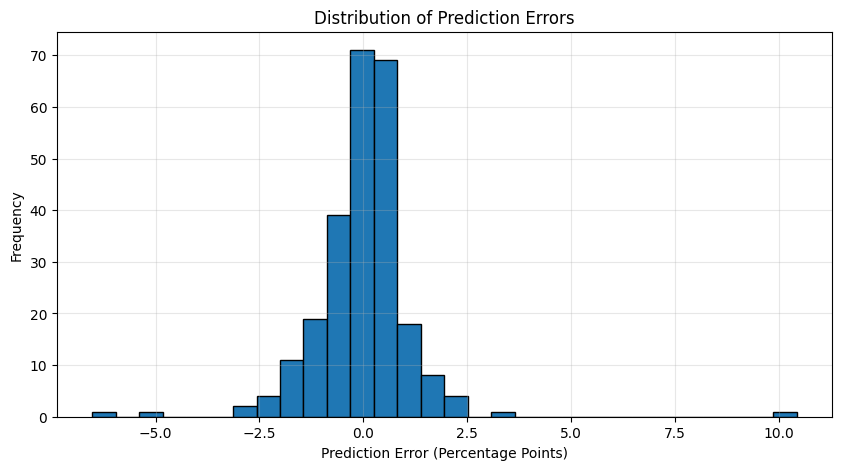

In [15]:

# Step 17: Analyze prediction errors

predictions["Error"] = (
    predictions["Actual_Return"]
    - predictions["Predicted_Return"]
)

plt.figure(figsize=(10, 5))

plt.hist(
    predictions["Error"] * 100,
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error (Percentage Points)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.show()


In [17]:

# Step 18: Model validation tests

# Test 1: Training data ends before test data begins
test1 = X_train.index.max() < X_test.index.min()

# Test 2: No missing feature values
test2 = (
    not X_train.isna().any().any()
    and not X_test.isna().any().any()
)

# Test 3: Predictions are finite
test3 = np.isfinite(y_pred).all()

# Test 4: Predictions match test-set length
test4 = len(y_pred) == len(y_test)

# Test 5: Features and targets have matching indices
test5 = (
    X_train.index.equals(y_train.index)
    and X_test.index.equals(y_test.index)
)


# Test 6: Training targets stay before 2025

# Identify the date of the next trading day
next_trading_day = pd.Series(
    df.index,
    index=df.index
).shift(-1)

# Find the target dates for training observations
training_target_dates = next_trading_day.loc[
    train.index
]

# Confirm all training targets are before 2025
test6 = (
    training_target_dates.notna().all()
    and (
        training_target_dates
        < pd.Timestamp("2025-01-01")
    ).all()
)

print(
    "Training Boundary Separation:",
    "PASSED" if test6 else "FAILED"
)

print("Last training feature date:", train.index.max())
print("Last training target date:", training_target_dates.max())


tests = {
    "Chronological Train/Test Split": test1,
    "No Missing Features": test2,
    "Finite Predictions": test3,
    "Prediction Length Consistency": test4,
    "Feature/Target Index Alignment": test5,
    "Training Boundary Separation": test6
}

for name, passed in tests.items():
    print(f"{name}: {'PASSED' if passed else 'FAILED'}")

assert all(tests.values()), "Validation failed."


Training Boundary Separation: PASSED
Last training feature date: 2024-12-30 00:00:00
Last training target date: 2024-12-31 00:00:00
Chronological Train/Test Split: PASSED
No Missing Features: PASSED
Finite Predictions: PASSED
Prediction Length Consistency: PASSED
Feature/Target Index Alignment: PASSED
Training Boundary Separation: PASSED


In [18]:

print("FINAL RESULTS")
print("-" * 35)

print(f"Linear Regression MAE: {mae:.4%}")
print(f"Baseline MAE: {baseline_mae:.4%}")

print(f"Linear Regression RMSE: {rmse:.4%}")
print(f"Baseline RMSE: {baseline_rmse:.4%}")

print(f"Model R-squared: {model_r2:.4f}")

print(f"Directional Accuracy: {directional_accuracy:.2%}")
print(f"Always-Positive Baseline: {positive_baseline_accuracy:.2%}")


FINAL RESULTS
-----------------------------------
Linear Regression MAE: 0.7400%
Baseline MAE: 0.7486%
Linear Regression RMSE: 1.2161%
Baseline RMSE: 1.2296%
Model R-squared: 0.0183
Directional Accuracy: 56.22%
Always-Positive Baseline: 57.43%
